[[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]]
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
2.0
2.0
2.0
2.0
2.0
2.0
2.0
2.0
2.0
2.0
2.0
2.0
2.0
[[0, 0], [0.25000000000000006, 0.4330127018922193], [0.7886751345948129, 0.5], [0.813194187433142, 0.9084936490538903], [1.3976224975010094, 0.8962341226347258], [1.3245054361836466, 1.2941107103712532], [1.

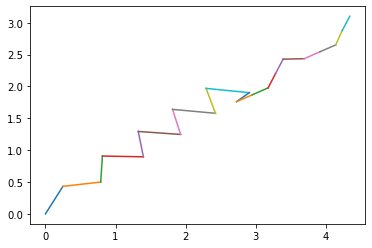

In [4]:
import numpy as np
import matplotlib.pyplot as plt
#First define the dimensions:
width=10
height=5

#And the grid distance:
delta_x=0.5
delta_y=0.5

#Now we define the refraction index:
#By default it will be all ones, but we can use a function

n=np.ones((int(width/delta_x),int(height/delta_y))) #w*h matrix full of 1

#We put 2's in the las rows/colums:
for i in range(int(len(n[:,0])/2)):
    for j in range(int(len(n[0,:]))):
        n[(len(n[:,0])-i-1),(len(n[0,:])-j-1)]+=1
print(n)

#We choose the initial position and angle of the ray:
ray=[[0,0]]
angle=60*np.pi/180

#We select the velocity of the light:
c=1

#We just do iterations:
step_t=0.5 #constant, time passing between iterations
i=0
current_index=0 #To see in which pixel we are
sum_h=0 #The sum of the height, to see if it passes to the next pixel
while i<width/step_t:
    i+=1
    #The n index depends on the height:
    n0=n[current_index,0]
    x=step_t*c/n0*np.cos(angle)
    y=step_t*c/n0*np.sin(angle)
    print(n0)
    #We need to see if we have reached the next height with this last step
    #To do so, we check if the sum is bigger than the grid size:
    sum_h+=y
    if (sum_h>delta_y):
        current_index+=1 #We go to the next grid
        n1=n[current_index,0]
        print(n1)
        #Snell law to calculate new angle.
        #CAUTION: Snell angle is taken from the normal and ours is from the horizontal axis:
        #We need to do sin(90-theta)=cos(theta)
        angle0=angle
        angle=np.arcsin((n0*np.cos(angle))/n1)
        #Now we need to calculate the height.
        #It divides into two heights:
        #1)height in previous cell: delta_y-sum_h
        #2)height in new cell with new angle and n:
        y1=(delta_y-sum_h)
        y2=(c/n1)*np.sin(angle)*(step_t-((delta_y-sum_h)/(c/n0)))
        y=y1+y2
        x=(y1/np.tan(angle0))+(y2/np.tan(angle))
        #We put the sum back to current height in next cell, to count again:
        sum_h=y2 
        #We add the new total position of our ray:
        ray.append([ray[i-1][0]+x,ray[i-1][1]+y])
        
    else:
        #If it doesn't jump to next cell the ray will travel normally:
        ray.append([ray[i-1][0]+x,ray[i-1][1]+y])
print(ray)

for j in range(len(ray)-1):
    x=[ray[j][0],ray[j+1][0]]
    y=[ray[j][1],ray[j+1][1]]
    plt.plot(x,y)